# Backlog v6: frozen inferred-strength transfer

The compact source-strength family and all parameters were frozen on training /
development before confirmation votes. This cohort was historically inspected;
the result is a frozen transfer check rather than untouched validation. E08 is
conditional on the actual quality gate. No competition submission is made here.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
REPO=Path.cwd().resolve()
if not (REPO/'GOAL.md').exists():REPO=REPO.parent
RESULTS=REPO/'results/span_006'
def read(name):return json.loads((RESULTS/name).read_text())
FIGURES=Path.home()/'database/llm_classification_finetuning/runs/span_006/figures'
FIGURES.mkdir(parents=True,exist_ok=True)
def save(fig,name):
    for suffix in ['png','svg']:fig.savefig(FIGURES/(name+'.'+suffix),dpi=160,bbox_inches='tight')
    plt.show()
result=read('H46_results.json');recipe=read('frozen_recipe.json');config=json.loads((REPO/'configs/span_006.json').read_text())
registry=json.loads((REPO/'backlog/hypotheses.json').read_text());v6=next(v for v in registry['versions'] if v['number']==6);items={i['id']:i for i in registry['items']}
print('v6 state:',v6['state'],'focus:',v6['focus_ids'])
display(pd.DataFrame([{'task':k,'status':items[k]['status'],'title':items[k]['title']} for k in v6['focus_ids']]))
print('Original execution clock:',config['started_at'],'deadline:',config['deadline'])
print('Freeze:',recipe['frozen_at'],'confirmation votes read at freeze:',recipe['confirmation_votes_read'])
print('Source fit answers:',recipe['source_fit_answers'],'purged against both cohorts:',recipe['purged_against_dev_and_confirmation'])
print('Transfer coverage:',result['rows'],'rows /',result['groups'],'prompt groups')


v6 state: closed focus: ['H46', 'E08']


,task,status,title
0,H46,done,Freeze and replicate inferred-strength correct...
1,E08,deferred,Qualify classifier plus inferred-strength corr...


Original execution clock: 2026-11-05T10:03:27+00:00 deadline: 2026-11-07T10:03:27+00:00
Freeze: 2026-11-05T10:29:56.823525+00:00 confirmation votes read at freeze: False
Source fit answers: 90889 purged against both cohorts: 1081
Transfer coverage: 5746 rows / 5174 prompt groups


## H46: the prespecified candidate against matched frozen controls

The only candidate is compact inferred strength. Source / residual fitting and
regularization selection used training / development only. No family, threshold
or parameter is changed from the confirmation result. Positive gain means lower
loss; intervals resample prompt groups conditional on frozen predictions.


,method,log_loss,accuracy,tie_loss,tie_recall,tie_auc
0,frozen_classifier,0.947161,0.542116,1.053275,0.397523,0.691185
1,calibration,0.946628,0.543334,1.059188,0.386824,0.691694
2,style,0.945815,0.544379,1.058616,0.386824,0.691777
3,strength,0.945753,0.542812,1.059589,0.379505,0.691815
4,shuffled,0.946722,0.545249,1.059432,0.390766,0.691873
5,source_only,1.077980,0.420640,1.184446,0.000000,0.499989
6,training_prior,1.097234,0.349112,1.174369,0.000000,0.500000
7,uniform,1.098612,0.349112,1.098612,0.000000,0.500000
8,majority_clipped_1e_12,17.984688,0.349112,27.631021,0.000000,0.500000


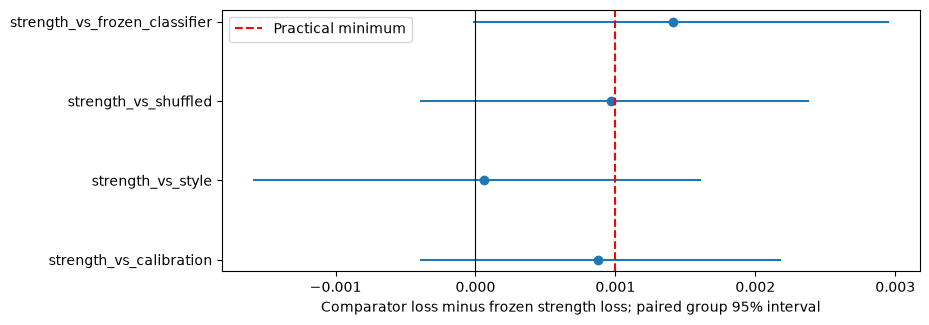

Quality gate: {'passed': False, 'rule': 'Fixed strength gain>=0.001 and95%lower>0 versus calibration, positive95%evidence versus style, full valid coverage and conditional runtime<=25200s.'}


In [2]:
display(pd.DataFrame([{'method':k,'log_loss':v['log_loss'],'accuracy':v['accuracy'],'tie_loss':v['class_loss'][2],
                      'tie_recall':v['class_recall'][2],'tie_auc':v['tie_auc']} for k,v in result['metrics'].items()]))
fig,ax=plt.subplots(figsize=(9,3.4));names=list(result['contrasts'])
for i,name in enumerate(names):
    r=result['contrasts'][name];lo,hi=r['interval_95'];ax.plot([lo,hi],[i,i],color='C0');ax.scatter(r['gain'],i,color='C0')
ax.set_yticks(range(len(names)),names);ax.axvline(0,color='black',linewidth=.8);ax.axvline(.001,color='red',linestyle='--',label='Practical minimum')
ax.set_xlabel('Comparator loss minus frozen strength loss; paired group 95% interval');ax.legend()
save(fig,'frozen_transfer_gain')
print('Quality gate:',result['gate'])


## Class behavior and source diagnostics

Source-class accuracy is a different metric from preference accuracy. Source names
are consulted only after predictions for descriptive diagnostics. The frozen
predictor consumes response text and source probabilities, not held-out names.


,method,A winner,B winner,Tie
0,calibration,0.901579,0.890856,1.059188
1,style,0.900213,0.890389,1.058616
2,strength,0.899356,0.890201,1.059589


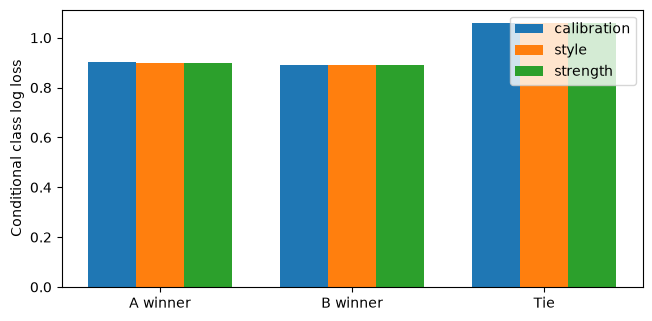

Source diagnostics: {'accuracy': 0.27984684998259657, 'source_log_loss': 2.860599994659424, 'mean_entropy': 2.8968677520751953, 'source_names_used_only_after_prediction': True}
Head swap errors: {'calibration': 0.0, 'style': 0.0, 'strength': 0.0, 'shuffled': 0.0}
Raw classifier order: {'decision_disagreement': 0.24921684650191436, 'mean_probability_l1': 0.22056494486882583, 'second_position_advantage': -0.01241328185759051}


,cohort,rows,clipped_source_fraction,source_accuracy,source_loss,strength_correlation,strength_rmse,source_distribution_TV
0,train,45985,0.034979,NaN,NaN,NaN,NaN,0.000000
1,dev,5746,0.039158,0.283241,2.85618,0.593544,0.487053,0.027256
2,confirmation,5746,0.032283,0.279847,2.86060,0.585027,0.477442,0.032458


,source_confidence_low,source_confidence_high,rows,gain
0,0.00,0.10,187,0.000286
1,0.10,0.20,2143,0.000763
2,0.20,0.35,1947,0.000383
3,0.35,0.50,906,0.001605
4,0.50,1.00,563,0.002030


Inspected cohorts and descriptive slices. Bin gains are not validated gates or deployment evidence.


In [3]:
methods=['calibration','style','strength'];labels=['A winner','B winner','Tie']
display(pd.DataFrame([{'method':name,**dict(zip(labels,result['metrics'][name]['class_loss']))} for name in methods]))
fig,ax=plt.subplots(figsize=(7.5,3.6));x=np.arange(3);width=.25
for i,name in enumerate(methods):ax.bar(x+(i-1)*width,result['metrics'][name]['class_loss'],width,label=name)
ax.set_xticks(x,labels);ax.set_ylabel('Conditional class log loss');ax.legend()
save(fig,'transfer_class_losses')
print('Source diagnostics:',result['source_diagnostics'])
print('Head swap errors:',result['head_swap_max_error'])
print('Raw classifier order:',result['raw_classifier_order'])
shift=read('descriptive_shift.json')
display(pd.DataFrame([{'cohort':k,'rows':v['rows'],'clipped_source_fraction':v['source_input_clipped_fraction'],
                      'source_accuracy':v.get('source_accuracy'),'source_loss':v.get('source_log_loss'),
                      'strength_correlation':v.get('inferred_strength_pearson'),'strength_rmse':v.get('inferred_strength_rmse'),
                      'source_distribution_TV':v['source_name_total_variation_from_training']} for k,v in shift['cohorts'].items()]))
display(pd.DataFrame(shift['confirmation_confidence_bins']))
print(shift['warning'])


## Resource use and conditional offline qualification

Charge includes setup and controls; two T4s for one elapsed hour count as one
session-hour. Runtime projection assumes 25,000 hidden comparisons and uses a
conservative classifier rate, local CPU source rate, measured setup, 20% margin
and 600-second reserve. E08 cannot run solely because H46 has a done status.


,stage,charged_seconds,ceiling_seconds
0,H46 GPU,3932.151,5400
1,E08 GPU,0.000,2700


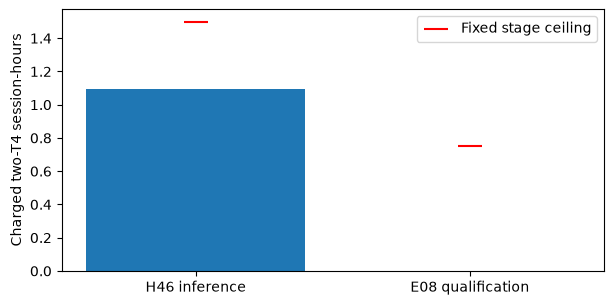

CPU source/meta freeze: 554.2020769400988 seconds; peak RSS: 3.6987876892089844 GiB
Measured prediction/source rates: 0.6527916988221372 0.0011849854555856397
Conditional joint projection: 20436.05999243725 seconds
Assumed25000hidden rows, measured prior/current classifier rate and local CPU source rate,20%margin,600sreserve. End-to-end offline profile still required.
E08: {'task': 'E08', 'at': '2026-11-05T11:43:48.098703+00:00', 'new_official_submissions': 0, 'H46_gate_passed': False, 'source_sha256': '795a664d0e0170e57106df1f0a6731b20dc95c6c0c6bde4860d8aff7e124430e', 'status': 'deferred', 'executed': False, 'passed': False, 'charged_gpu_seconds': 0, 'reason': 'H46 did not pass its prespecified quality gate; the conditional offline qualification was not executed.'}


In [4]:
decisions=read('decisions.json')
e08=read('E08_results.json')
display(pd.DataFrame([{'stage':'H46 GPU','charged_seconds':result['charged_gpu_seconds'],'ceiling_seconds':config['job_seconds_caps']['confirmation']},
                      {'stage':'E08 GPU','charged_seconds':e08.get('charged_gpu_seconds',0),'ceiling_seconds':config['job_seconds_caps']['offline_profile']}]))
fig,ax=plt.subplots(figsize=(7,3.4));stage=['H46 inference','E08 qualification'];charge=[result['charged_gpu_seconds'],e08.get('charged_gpu_seconds',0)]
ax.bar(stage,np.array(charge)/3600,color=['C0','C1']);ax.scatter(stage,np.array([5400,2700])/3600,marker='_',s=300,color='red',label='Fixed stage ceiling')
ax.set_ylabel('Charged two-T4 session-hours');ax.legend();save(fig,'transfer_compute')
print('CPU source/meta freeze:',recipe['cpu_elapsed_seconds'],'seconds; peak RSS:',recipe['peak_rss_gib'],'GiB')
print('Measured prediction/source rates:',result['classifier_seconds_per_row'],result['source_seconds_per_answer'])
print('Conditional joint projection:',result['projected_joint_seconds'],'seconds')
print(result['projection_note']);print('E08:',e08)


## Audit and version boundary

Read per-task reports for failures, stopping decisions and uncertainty. The
original data/splits/model and earlier snapshots are preserved. All live jobs are
finished before closure. Stop at the next-version boundary without new submission.


In [5]:
for name in ['decisions.json','scientific_audit.json','terminal_audit.json']:
    if (RESULTS/name).exists():
        value=read(name);print(name,{k:v for k,v in value.items() if k not in ['inventory','artifact_sha256','old_snapshot_sha256','jobs']})
        if 'inventory' in value:print('Closing quota:',value['inventory']['quota'])
display(pd.DataFrame([{'version':v['number'],'state':v['state'],'tasks':len(v['item_ids']),'focus':v['focus_ids']} for v in registry['versions']]))
print('Official score unchanged:',result['official_score_unchanged'])
print('Figures:',FIGURES)


decisions.json {'span': 6, 'focus': ['H46', 'E08'], 'H46': {'status': 'done', 'quality_gate_passed': False, 'primary_loss': 0.9457526229111632, 'primary_gain': {'gain': 0.0008756688803934023, 'interval_95': [-0.0003898768565268832, 0.002173203435911227], 'groups': 5174, 'rows': 5746, 'replicates': 2000}, 'gain_vs_style': {'gain': 6.27523133456308e-05, 'interval_95': [-0.001584026390711396, 0.0016041419268757787], 'groups': 5174, 'rows': 5746, 'replicates': 2000}, 'post_hoc_promotion': False}, 'E08': {'status': 'deferred', 'executed': False, 'charged_gpu_seconds': 0, 'reason': 'H46 did not pass its prespecified quality gate; the conditional offline qualification was not executed.'}, 'best_official_log_loss': 0.95481, 'new_submissions': 0, 'charged_gpu_seconds': 3932.150999999998, 'gpu_cap_seconds': 8100, 'cpu_freeze_seconds': 554.2020769400988, 'cpu_evaluate_seconds': 4.048076999839395, 'confirmation_historically_inspected': True, 'scientific_audit_passed': True, 'parameters_frozen_befo

,version,state,tasks,focus
0,1,closed,41,"[E00, H01, H09, H04, H11]"
1,2,closed,39,"[H40, E01, H03, H37, H42]"
2,3,closed,37,"[E03, H39, E02, H43]"
3,4,closed,35,"[E04, H44]"
4,5,closed,38,"[E06, E07, H45]"
5,6,closed,37,"[H46, E08]"
6,7,active,37,[]
7,8,draft,0,[]


Official score unchanged: 0.95481
Figures: /home/tarstars/database/llm_classification_finetuning/runs/span_006/figures
